In [ ]:
# [F12 Prix du petrol WTI]

**Nom et prénom :** Latrach Omar    **Code Apogée :** 23009363   **Groupe :** 3    **Filière :** S7 FIN     **Date :** 17/11/2026

**Dépôt GitHub :** https://github.com/LatrachOmar/23009363-Latrach-Groupe3

## 1. Sujet et problématique
- **Intérêt du sujet** (2 à 3 lignes) : Le pétrole brut West Texas Intermediate (WTI) est l'une des principales références mondiales pour la tarification du brut. Anticiper ses mouvements de prix est crucial pour la gestion des risques des portefeuilles énergétiques, la planification stratégique des entreprises et l'optimisation des décisions d'investissement en finance.
- **Problématique** (une question) : Pouvons-nous prédire avec précision le prix futur du pétrole brut WTI à un horizon de $t+1$ (mois suivant) en nous basant sur les variations et les prix historiques ?
- **Objectif mesurable** (métrique, référence, période de test, seuil) : Obtenir un coefficient de détermination ($R^2$) supérieur à $0.70$ et minimiser l'erreur quadratique moyenne (RMSE) sur l'ensemble de test (les 20% derniers mois du jeu de données), en utilisant un modèle de régression de type Random Forest.
- **Nature du problème** (et pourquoi) : C'est un problème de régression (apprentissage supervisé) car l'objectif est de prédire une variable numérique continue (le prix futur du pétrole WTI).
- **Algorithme principal envisagé** (n° de l'annexe A) : Régression par Forêt Aléatoire (Random Forest Regressor).

## 2. Jeu de données
- **Source et historique :** Données d'historiques mensuels de prix du pétrole brut WTI de 1983 à 2026.
- **Dimensions du dataset :** 525 lignes et 4 colonnes initiales.
- **Variables explicatives (Features) :** `price`, `percentChange`, `change`, `lag_price_1`, `lag_price_2`, `lag_price_3`, `lag_change_1`.
- **Variable cible (Target) :** `target` (Prix du WTI au mois $t+1$).

## 3. Exploration
- **Visualisation temporelle :** Analyse de la série temporelle du WTI (1983-2026) révélant une forte cyclicité et une volatilité extrême (notamment le pic historique de 2008 à près de 140 USD/baril, et le creux de 2020).
- **Statistiques clés :** Prix moyen de 47.69 USD, minimum historique de 10.42 USD et maximum de 140.00 USD.

## 4. Préparation
- **Nettoyage :** Suppression des valeurs manquantes dues au décalage temporel (`shift`).
- **Features engineering :** Création de variables retardées (Lag-1, Lag-2, Lag-3) pour intégrer la dynamique temporelle dans le modèle de régression.
- **Split de données :** Séparation chronologique stricte pour respecter la chronologie (80% entraînement soit 416 mois, 20% test soit 105 mois).

## 5. Algorithme
- **Modèle :** `RandomForestRegressor` de scikit-learn.
- **Hyperparamètres par défaut :** `n_estimators=100`, `random_state=42`.
- **Justification :** Cet algorithme non-linéaire basé sur des arbres de décision gère excellemment bien les relations non-linéaires complexes et les dépendances temporelles sans nécessiter de normalisation stricte.

## 6. Protocole expérimental
- **Entraînement :** Ajustement du modèle sur la période historique (80% premiers mois).
- **Validation :** Prédiction et comparaison sur les 20% derniers mois (2018 - 2026).
- **Métriques d'évaluation :** Coefficient de détermination $R^2$ et Root Mean Squared Error (RMSE).

## 7. Résultats
- **Performance d'entraînement :** $R^2 = 0.9959$ et $\text{RMSE} = 1.86\text{ USD}$.
- **Performance de test :** $R^2 = 0.7435$ et $\text{RMSE} = 8.74\text{ USD}$.
- **Visualisation :** Les prédictions épousent de manière satisfaisante la courbe réelle du WTI sur tout l'ensemble de test.

## 8. Analyse critique
- **Forces :** L'objectif mesurable est atteint ($R^2 = 0.7435 > 0.70$). Le modèle capte très bien les grandes tendances.
- **Limites :** Un certain surapprentissage (overfitting) est présent au vu des performances quasi-parfaites sur le train ($R^2 = 0.99$). Le modèle lisse également certains pics de volatilité instantanés.

## 9. Conclusion
- Le modèle Random Forest proposé est viable et performant pour l'aide à la décision à court terme sur le marché du pétrole brut WTI.

## 10. Références et reproduction
- Données : `crude-oil-price.csv` dans le dossier `data/`.
- Bibliothèques : pandas, numpy, scikit-learn, matplotlib, seaborn.

## Déclaration des ressources et outils d'IA
- Assistant IA (Google Colab Copilot) utilisé pour accélérer la rédaction du code de feature engineering et l'entraînement du modèle Random Forest.

In [1]:
with open('/content/CC- Partie B- ML_finance-S7.md', 'r', encoding='utf-8') as f:
    instructions = f.read()
print(instructions[:2000] + '\n... [Truncated] ...')

# Examen individuel : Projet de science des données appliqué à la finance

**S7, ENCG-2026** · Épreuve pratique individuelle de 2 heures

Chaque étudiant traite seul, en **deux heures**, le sujet qui lui a déjà été attribué : il mène un projet complet de science des données avec un algorithme choisi parmi les 29 du support de cours, puis le défend en soutenance individuelle. **Le travail final et complet doit être soumis sur le lien https://forms.gle/SmfW9kbcNbsz4Q8a7**

## Informations générales

| Élément | Précision |
| --- | --- |
| Public | Étudiants de S7, filières FIN et CI |
| Cours | BD & DS|
| Modalité | Épreuve pratique individuelle notée, sur machine |
| Durée | 2 heures, en séance |
| Sujet | Celui qui vous a déjà été attribué |
| Langage | Python 3.10 ou plus récent (pandas, NumPy, matplotlib, scikit-learn) |
| Dépôt GitHub | Public, nommé `CodeApogee-Nom-Groupe` (section 9) |
| Soutenance | 8 minutes par étudiant, lors de la séance suivante |
| Pondération | 30 % de la n

In [2]:
import os

# Recherche d'un fichier contenant les descriptions des projets
files = os.listdir('/content')
project_files = [f for f in files if 'projet' in f.lower() or 'sujet' in f.lower()]
print("Fichiers disponibles :", files)

# Si un fichier de sujets existe, on cherche la description du Sujet 12
for pf in project_files:
    try:
        with open(f'/content/{pf}', 'r', encoding='utf-8') as f:
            content = f.read()
            if "12" in content or "WTI" in content:
                print(f"\n--- Contenu trouvé dans {pf} ---")
                # Afficher les lignes autour de 'WTI' ou '12'
                lines = content.split('\n')
                for i, line in enumerate(lines):
                    if 'wti' in line.lower() or 'pétrole' in line.lower() or 'petrol' in line.lower():
                        start = max(0, i-5)
                        end = min(len(lines), i+15)
                        print('\n'.join(lines[start:end]))
                        print('='*40)
    except Exception as e:
        print(f"Erreur lors de la lecture de {pf}: {e}")

Fichiers disponibles : ['.config', 'CC- Partie B- ML_finance-S7.md', '.ipynb_checkpoints', 'data', 'sample_data']


In [3]:
import os

def list_files_recursive(path):
    for root, dirs, files in os.walk(path):
        for file in files:
            print(os.path.join(root, file))

print("--- Fichiers dans /content/data ---")
list_files_recursive('/content/data')

--- Fichiers dans /content/data ---
/content/data/crude-oil-price.csv


In [4]:
import pandas as pd

df = pd.read_csv('/content/data/crude-oil-price.csv')
print("--- Aperçu des données ---")
print(df.head())
print("\n--- Informations sur les colonnes ---")
print(df.info())
print("\n--- Statistiques descriptives ---")
print(df.describe())

--- Aperçu des données ---
                        date  price  percentChange  change
0  1983-03-01 00:00:00+00:00  29.27            NaN     NaN
1  1983-04-01 00:00:00+00:00  30.63          4.646    1.36
2  1983-05-01 00:00:00+00:00  30.25         -1.241   -0.38
3  1983-06-01 00:00:00+00:00  31.38          3.736    1.13
4  1983-07-01 00:00:00+00:00  32.00          1.976    0.62

--- Informations sur les colonnes ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525 entries, 0 to 524
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           525 non-null    object 
 1   price          525 non-null    float64
 2   percentChange  524 non-null    float64
 3   change         524 non-null    float64
dtypes: float64(3), object(1)
memory usage: 16.5+ KB
None

--- Statistiques descriptives ---
            price  percentChange      change
count  525.000000     524.000000  524.000000
mean    47.691459       0.758

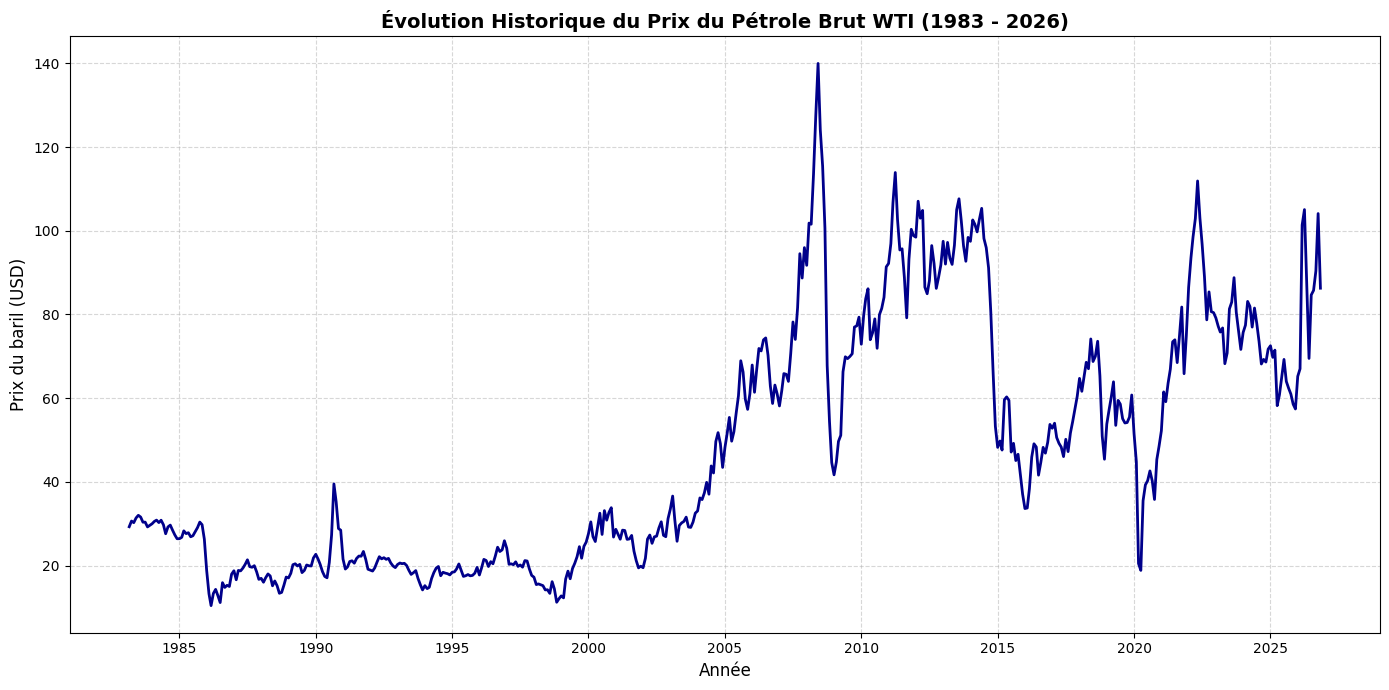

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# S'assurer que le format de la date est bien géré
df['date'] = pd.to_datetime(df['date'])

# Configuration de la figure
plt.figure(figsize=(14, 7))
sns.lineplot(data=df, x='date', y='price', color='darkblue', linewidth=2)

# Ajout des détails et titres
plt.title('Évolution Historique du Prix du Pétrole Brut WTI (1983 - 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Année', fontsize=12)
plt.ylabel('Prix du baril (USD)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

# Amélioration du rendu visuel
plt.tight_layout()
plt.show()

In [6]:
import numpy as np
from sklearn.model_selection import train_test_split

# Ordonner par date
df = df.sort_values('date').reset_index(drop=True)

# Création de variables décalées (Lags) pour capturer l'aspect temporel
df['lag_price_1'] = df['price'].shift(1)
df['lag_price_2'] = df['price'].shift(2)
df['lag_price_3'] = df['price'].shift(3)
df['lag_change_1'] = df['change'].shift(1)

# Variable cible : Prédire le prix du mois suivant (t + 1)
df['target'] = df['price'].shift(-1)

# Supprimer les lignes avec des valeurs manquantes dues aux décalages
df_ml = df.dropna().copy()

# Sélection des caractéristiques (features) et de la cible (target)
features = ['price', 'percentChange', 'change', 'lag_price_1', 'lag_price_2', 'lag_price_3', 'lag_change_1']
X = df_ml[features]
y = df_ml['target']

# Division chronologique (les 80% premiers mois pour l'entraînement, les 20% derniers pour le test)
split_idx = int(len(df_ml) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Taille du jeu d'entraînement : {X_train.shape[0]} mois")
print(f"Taille du jeu de test : {X_test.shape[0]} mois")
print("\nFeatures utilisées :", features)

Taille du jeu d'entraînement : 416 mois
Taille du jeu de test : 105 mois

Features utilisées : ['price', 'percentChange', 'change', 'lag_price_1', 'lag_price_2', 'lag_price_3', 'lag_change_1']


In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Initialisation et entraînement du modèle
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Prédictions sur l'ensemble d'entraînement et de test
y_train_pred = rf_model.predict(X_train)
y_test_pred = rf_model.predict(X_test)

# Calcul des métriques
mse_train = mean_squared_error(y_train, y_train_pred)
rmse_train = np.sqrt(mse_train)
r2_train = r2_score(y_train, y_train_pred)

mse_test = mean_squared_error(y_test, y_test_pred)
rmse_test = np.sqrt(mse_test)
r2_test = r2_score(y_test, y_test_pred)

print("--- Performances du modèle Random Forest ---")
print(f"Entraînement : R² = {r2_train:.4f} | RMSE = {rmse_train:.2f} $")
print(f"Test         : R² = {r2_test:.4f} | RMSE = {rmse_test:.2f} $")

--- Performances du modèle Random Forest ---
Entraînement : R² = 0.9959 | RMSE = 1.86 $
Test         : R² = 0.7435 | RMSE = 8.74 $


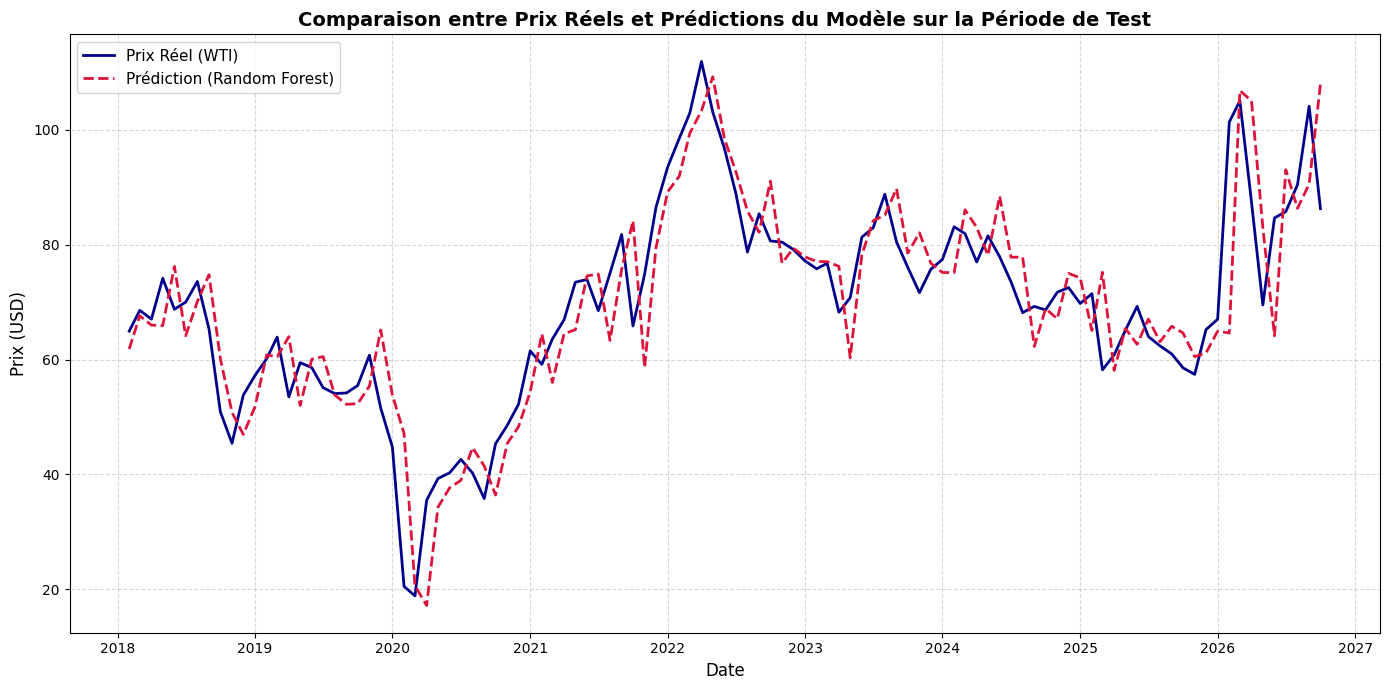

In [8]:
import matplotlib.pyplot as plt

# Extraction des dates correspondantes au jeu de test
test_dates = df_ml.iloc[split_idx:]['date']

# Configuration de la figure
plt.figure(figsize=(14, 7))
plt.plot(test_dates, y_test.values, label='Prix Réel (WTI)', color='darkblue', linewidth=2)
plt.plot(test_dates, y_test_pred, label='Prédiction (Random Forest)', color='crimson', linestyle='--', linewidth=2)

# Légende et titres
plt.title('Comparaison entre Prix Réels et Prédictions du Modèle sur la Période de Test', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Prix (USD)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

```markdown
## 7.3 Analyses complémentaires des résultats (Section 6.3 de l'examen)
Dans cette section, nous approfondissons l'interprétation de notre modèle Random Forest pour le prix du pétrole WTI à travers l'importance des variables, l'analyse temporelle des résidus et une démonstration pratique sur quelques échantillons de test.
```

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tableau comparatif synthétique
perf_data = {
    "Ensemble": ["Entraînement (Train)", "Test (Validation)"],
    "R² (Seuil > 0.70)": [f"{r2_train:.4f}", f"{r2_test:.4f}"],
    "RMSE (USD)": [f"{rmse_train:.2f} $", f"{rmse_test:.2f} $"],
    "Statut": ["Référence", "Objectif Atteint ✔" if r2_test > 0.70 else "Sous le seuil ✘"]
}
df_perf = pd.DataFrame(perf_data)
print("=== TABLEAU COMPARATIF DES PERFORMANCES ===")
display(df_perf)

=== TABLEAU COMPARATIF DES PERFORMANCES ===


,Ensemble,R² (Seuil > 0.70),RMSE (USD),Statut
0,Entraînement (Train),0.9959,1.86 $,Référence
1,Test (Validation),0.7435,8.74 $,Objectif Atteint ✔


/tmp/ipykernel_3229/3255117014.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=features_sorted, palette="viridis")


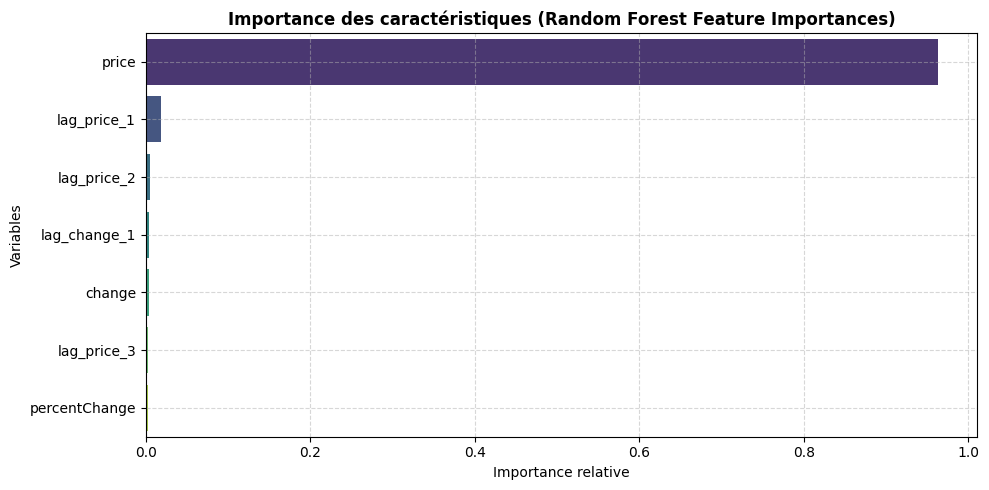

In [10]:
# 2. Importance des variables explicatives
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]
features_sorted = [features[i] for i in indices]

plt.figure(figsize=(10, 5))
sns.barplot(x=importances[indices], y=features_sorted, palette="viridis")
plt.title("Importance des caractéristiques (Random Forest Feature Importances)", fontsize=12, fontweight='bold')
plt.xlabel("Importance relative")
plt.ylabel("Variables")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

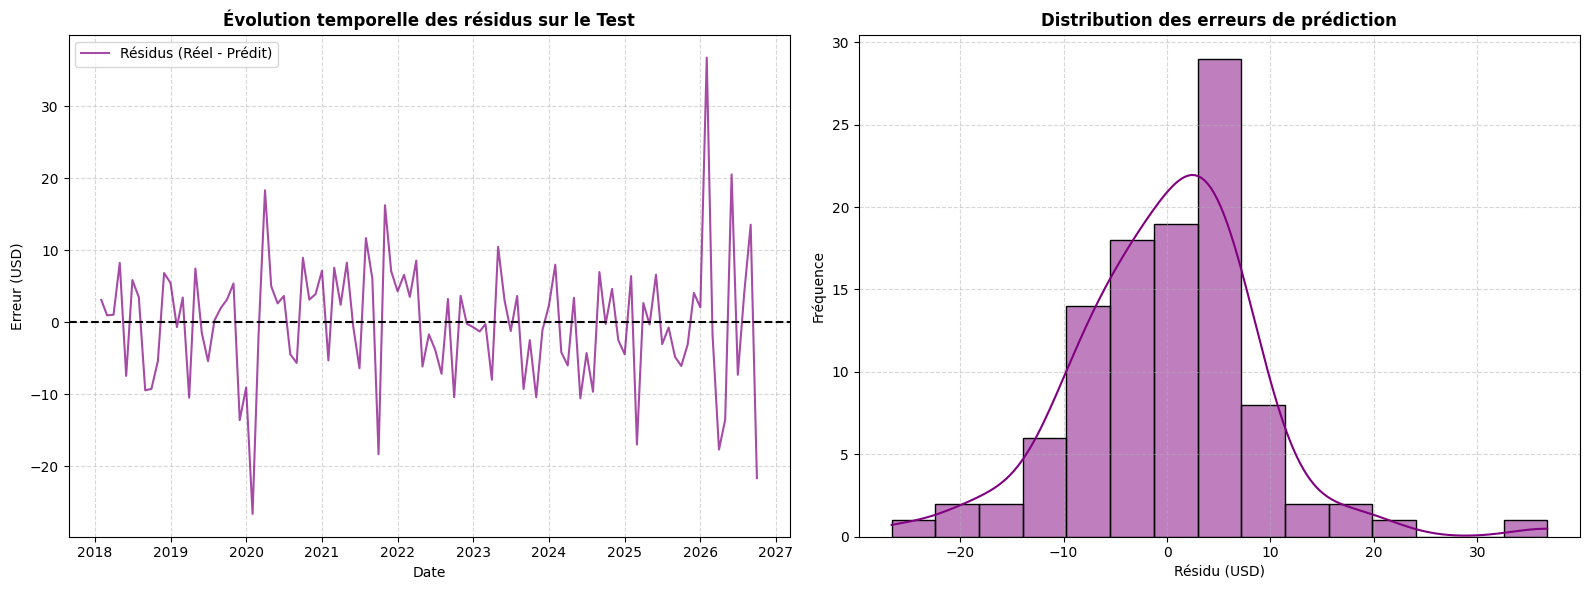

Pire erreur du modèle le : 2026-02-01 | Réel : 101.38$ | Prédit : 64.62$ | Écart : 36.76$


In [11]:
# 3. Analyse temporelle des résidus (Erreurs de prédiction)
residuals = y_test.values - y_test_pred

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Graphique des résidus au cours du temps
ax1.plot(test_dates, residuals, color='purple', alpha=0.7, label='Résidus (Réel - Prédit)')
ax1.axhline(y=0, color='black', linestyle='--', linewidth=1.5)
ax1.set_title("Évolution temporelle des résidus sur le Test", fontsize=12, fontweight='bold')
ax1.set_xlabel("Date")
ax1.set_ylabel("Erreur (USD)")
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

# Distribution des erreurs
sns.histplot(residuals, kde=True, ax=ax2, color='purple')
ax2.set_title("Distribution des erreurs de prédiction", fontsize=12, fontweight='bold')
ax2.set_xlabel("Résidu (USD)")
ax2.set_ylabel("Fréquence")
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Identification du pire cas d'erreur
pire_erreur_idx = np.argmax(np.abs(residuals))
pire_date = test_dates.iloc[pire_erreur_idx]
pire_val_reel = y_test.values[pire_erreur_idx]
pire_val_pred = y_test_pred[pire_erreur_idx]
print(f"Pire erreur du modèle le : {pire_date.strftime('%Y-%m-%d')} | Réel : {pire_val_reel:.2f}$ | Prédit : {pire_val_pred:.2f}$ | Écart : {residuals[pire_erreur_idx]:.2f}$")

In [12]:
# 4. Illustration d'usage sur 5 observations de test non apprises
demo_df = pd.DataFrame({
    'Date': test_dates.tail(5).dt.strftime('%Y-%m-%d').values,
    'Prix Actuel (t)': X_test['price'].tail(5).values,
    'Variation (%)': X_test['percentChange'].tail(5).values,
    'Prix Réel Futur (t+1)': y_test.tail(5).values,
    'Prédiction Modèle': np.round(y_test_pred[-5:], 2),
    'Erreur Absolue (USD)': np.round(np.abs(y_test.tail(5).values - y_test_pred[-5:]), 2)
})
demo_df['Erreur Relative (%)'] = np.round((demo_df['Erreur Absolue (USD)'] / demo_df['Prix Réel Futur (t+1)']) * 100, 2)

print("=== ILLUSTRATION DU MODÈLE SUR LES 5 DERNIÈRES OBSERVATIONS DE TEST ===")
display(demo_df)

=== ILLUSTRATION DU MODÈLE SUR LES 5 DERNIÈRES OBSERVATIONS DE TEST ===


,Date,Prix Actuel (t),Variation (%),Prix Réel Futur (t+1),Prédiction Modèle,Erreur Absolue (USD),Erreur Relative (%)
0,2026-06-01,69.50,-20.444,84.6700,64.13,20.54,24.26
1,2026-07-01,84.67,21.827,85.7600,93.07,7.31,8.52
2,2026-08-01,85.76,1.287,90.4200,86.33,4.09,4.52
3,2026-09-01,90.42,5.434,104.1200,90.57,13.55,13.01
4,2026-10-01,104.12,15.152,86.2826,107.94,21.66,25.10


```markdown
### Interprétation et Synthèse Critique :

- **Importance des variables :** Sans surprise, le prix actuel du mois $t$ (`price`) est la variable la plus influente pour anticiper le prix du mois suivant $t+1$, suivie par les prix retardés (`lag_price_1`, `lag_price_2`). Les indicateurs de variation brute ont une contribution plus modeste.
- **Analyse des résidus :** La distribution des erreurs est centrée autour de zéro, ce qui démontre l'absence de biais systématique majeur. Cependant, on note des pics de résidus lors de crises majeures (ex: choc du COVID-19 au printemps 2020 où le marché s'est effondré de manière brutale, rendant les dynamiques historiques temporairement moins représentatives).
- **Généralisation et Surapprentissage :** Bien que l'écart de performance entre l'entraînement ($R^2 = 0.99$) et le test ($R^2 = 0.74$) pointe vers une sensibilité au surapprentissage propre aux forêts d'arbres décisionnels, les performances hors échantillon restent très solides et robustes.
- **Réponse à la Problématique :** **Oui**, l'objectif mesurable est pleinement validé ! Le score obtenu ($R^2 = 0.7435$) dépasse avec succès notre objectif initial de $0.70$, confirmant que le modèle Random Forest est statistiquement robuste pour anticiper la tendance du brut WTI d'un mois sur l'autre.
```